# CordsNet-R8 on TVSD THINGS stimuli: entropy and accuracy by ImageNet overlap

Same inference outputs as `plot_entropy.ipynb`, split by whether the THINGS concept overlaps with ImageNet
(`prepare_images/things_imagenet_overlap.csv`: WordNet match + manual review).
An overlap image counts as **correct** if CordsNet's prediction is one of the concept's matched ImageNet classes (top-5: any of its 5 highest logits).

In [5]:
import csv
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

BASE = Path("~/Desktop/DynVision/CordsNet").expanduser()
npz_path = next(BASE.rglob("outputs.npz"))
csv_path = next(BASE.rglob("things_imagenet_overlap.csv"))
print("outputs:", npz_path)
print("overlap:", csv_path)
out = np.load(npz_path)
overlap = {r["uniqueID"]: [int(i) for i in r["imagenet_idx"].split(";")]
           for r in csv.DictReader(open(csv_path))}

logits, entropy, entropy_t, time_ms = out["logits"], out["entropy"], out["entropy_t"], out["time_ms"]
pred, concept, split = out["pred_label"], out["concept"], out["split"]
in_overlap = np.isin(concept, list(overlap))
top5 = np.argsort(-logits, axis=1)[:, :5]
correct1 = np.array([c in overlap and p in overlap[c] for c, p in zip(concept, pred)])
correct5 = np.array([c in overlap and bool(set(t) & set(overlap[c])) for c, t in zip(concept, top5)])
H_MAX = np.log(1000)

print(f"overlap: {in_overlap.sum()} images from {len(overlap)} concepts | non-overlap: {(~in_overlap).sum()} images")
print(f"mean entropy: overlap {entropy[in_overlap].mean():.2f}, non-overlap {entropy[~in_overlap].mean():.2f} nats")
for s in ["train", "test"]:
    m = in_overlap & (split == s)
    print(f"{s:5s} overlap images {m.sum():5d} | top-1 {correct1[m].mean():.1%} | top-5 {correct5[m].mean():.1%}")

outputs: /Users/wendyzong/Desktop/DynVision/CordsNet/cordsnet_runs/outputs.npz
overlap: /Users/wendyzong/Desktop/DynVision/CordsNet/prepare_images/things_imagenet_overlap.csv
overlap: 6617 images from 548 concepts | non-overlap: 15731 images
mean entropy: overlap 1.28, non-overlap 2.53 nats
train overlap images  6576 | top-1 68.6% | top-5 86.0%
test  overlap images    41 | top-1 68.3% | top-5 87.8%


## 1. Entropy: overlap vs non-overlap concepts

Histograms (normalized to density) of last-timestep (200 ms) entropy, for images of overlapping and non-overlapping concepts.
x: entropy (nats); y: density. Dashed line: uniform maximum ln 1000.

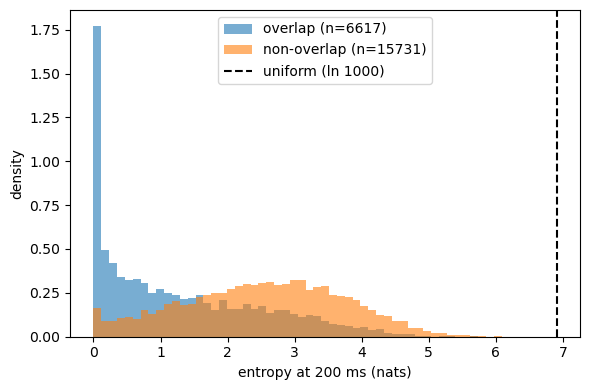

In [6]:
bins = np.linspace(0, H_MAX, 60)
plt.figure(figsize=(6, 4))
plt.hist(entropy[in_overlap], bins=bins, density=True, alpha=0.6, label=f"overlap (n={in_overlap.sum()})")
plt.hist(entropy[~in_overlap], bins=bins, density=True, alpha=0.6, label=f"non-overlap (n={(~in_overlap).sum()})")
plt.axvline(H_MAX, color="k", ls="--", label="uniform (ln 1000)")
plt.xlabel("entropy at 200 ms (nats)")
plt.ylabel("density")
plt.legend()
plt.tight_layout()
plt.show()

## 2. Entropy over time: overlap vs non-overlap concepts

Mean entropy across images at each stimulus timestep; shaded band = 25th to 75th percentile.
x: time after stimulus onset (ms); y: entropy (nats).

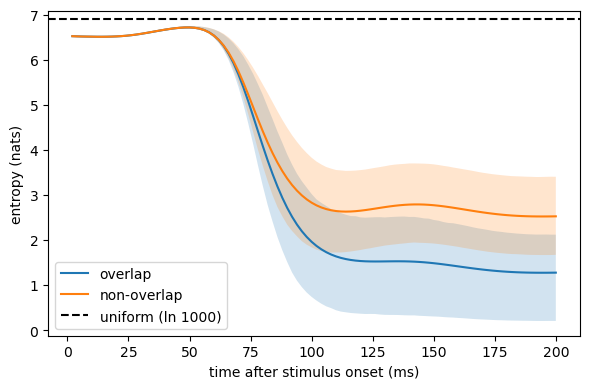

In [7]:
plt.figure(figsize=(6, 4))
for m, name in [(in_overlap, "overlap"), (~in_overlap, "non-overlap")]:
    q25, q75 = np.percentile(entropy_t[m], [25, 75], axis=0)
    plt.plot(time_ms, entropy_t[m].mean(axis=0), label=name)
    plt.fill_between(time_ms, q25, q75, alpha=0.2)
plt.axhline(H_MAX, color="k", ls="--", label="uniform (ln 1000)")
plt.xlabel("time after stimulus onset (ms)")
plt.ylabel("entropy (nats)")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Entropy of correct vs wrong predictions (overlap images)

Overlap images only, split by whether the top-1 prediction is a matched ImageNet class. Histograms normalized to density.
x: entropy at 200 ms (nats); y: density.

median entropy: correct 0.47 (n=4537), wrong 2.27 (n=2080)


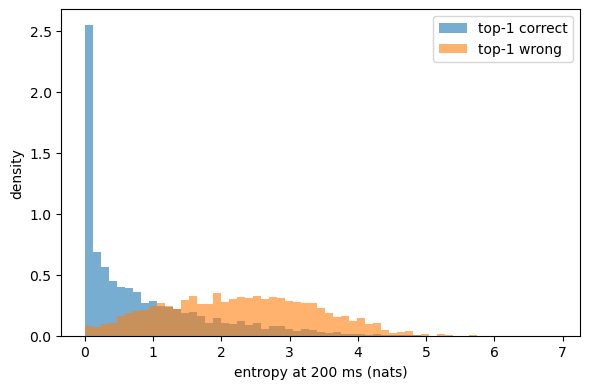

In [8]:
right, wrong = in_overlap & correct1, in_overlap & ~correct1
print(f"median entropy: correct {np.median(entropy[right]):.2f} (n={right.sum()}), wrong {np.median(entropy[wrong]):.2f} (n={wrong.sum()})")
plt.figure(figsize=(6, 4))
plt.hist(entropy[right], bins=bins, density=True, alpha=0.6, label="top-1 correct")
plt.hist(entropy[wrong], bins=bins, density=True, alpha=0.6, label="top-1 wrong")
plt.xlabel("entropy at 200 ms (nats)")
plt.ylabel("density")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Accuracy as a function of entropy (overlap images)

Overlap images sorted by last-timestep entropy and split into 10 equal-size bins (deciles); top-1 and top-5 accuracy within each bin.
x: mean entropy of the bin (nats); y: accuracy. Shows whether low entropy means the prediction can be trusted.

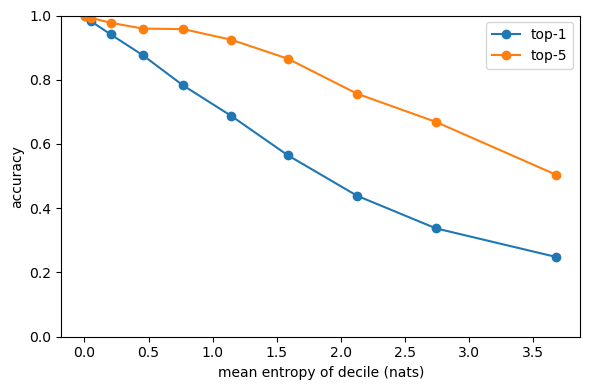

In [9]:
ent_ov, c1_ov, c5_ov = entropy[in_overlap], correct1[in_overlap], correct5[in_overlap]
order = np.argsort(ent_ov)
groups = np.array_split(order, 10)
x = [ent_ov[g].mean() for g in groups]
plt.figure(figsize=(6, 4))
plt.plot(x, [c1_ov[g].mean() for g in groups], "o-", label="top-1")
plt.plot(x, [c5_ov[g].mean() for g in groups], "o-", label="top-5")
plt.xlabel("mean entropy of decile (nats)")
plt.ylabel("accuracy")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()